In [ ]:
#!/usr/bin/env python3
import os, sys, time, logging
import numpy as np
import pandas as pd
import argparse
import matplotlib.pyplot as plt

# Import project modules
if "/mnt/research/ascsn/aaron-philip/barrier-extraction/src" not in sys.path:
    sys.path.append("/mnt/research/ascsn/aaron-philip/barrier-extraction/src")
from train import  init_E0, run_wong_trial, fit_wong_with_restarts, make_x_pred, draw_sigma_samples,percentile_bands, barrier_from_sigma_samples, fit_wong
from utils import load_packed_hdf5 # updated import
from wong import sigma

### Check 0: Checking the Dataset Generation Process

In [2]:
# Check 0: Are the generated datasets valid? 
# Check 0.0: Loading correctly? 
data_path = "/mnt/home/philipaa/scratch/barrier-paper-datasets/cv0.75_spacing1.0.h5"

ds = load_packed_hdf5(data_path)
N = ds['N']
N

1000

Text(0, 0.5, 'Cross-section (Sigma)')

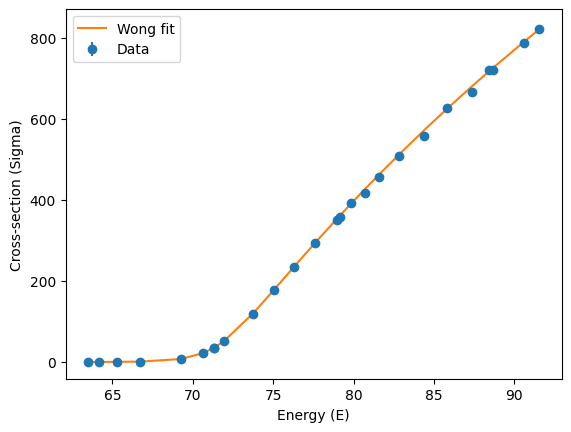

In [3]:
# Check 0.1: Wong parameters correctly correspond to data they generated
i = 419
E_i, Sigma_i, Sigma_err_i, params_i = ds["get_i"](i)
plt.errorbar(E_i, Sigma_i, yerr=Sigma_err_i, label='Data', fmt='o')
plt.plot(E_i, sigma(E_i, *params_i), '-', label='Wong fit')
plt.legend()
plt.xlabel('Energy (E)')
plt.ylabel('Cross-section (Sigma)')


### Check 1: Checking the Wong Fitting Procedure

In [4]:
# Check 1: Does the Wong fitting procedure work well enough?
# Check 1.0: Can we find the barrier location quickly? 

i = 582
E_i, Sigma_i, Sigma_err_i, params_i = ds["get_i"](i)
p0 = init_E0(E_i, Sigma_i)
print("Initial guess p0:", p0)
print("True params:", params_i)
# Conclusion: The initial guess for E0 generally works well

# Check 1.1: When the initial guess is off, can we still recover the correct parameters?
popt, pcov, chi2= run_wong_trial(E_i, Sigma_i, Sigma_err_i, p0)
print("Fitted params:", popt)
print("Chi2:", chi2)

# Conclusion: Even if the initial guess for E0 is off, we can still recover the correct parameters quickly.

Initial guess p0: [73.89809495287606, 11.0, 5.0]
True params: [64.64676747  9.98599952  6.71544977]
Fitted params: [64.65138989  9.99066788  6.71785916]
Chi2: 18.14186394357596


Fitted params: [77.25592549 10.67598703  6.34531855]
True params: [77.25473133 10.6833096   6.33971773]
Chi2: 24.209301616673056


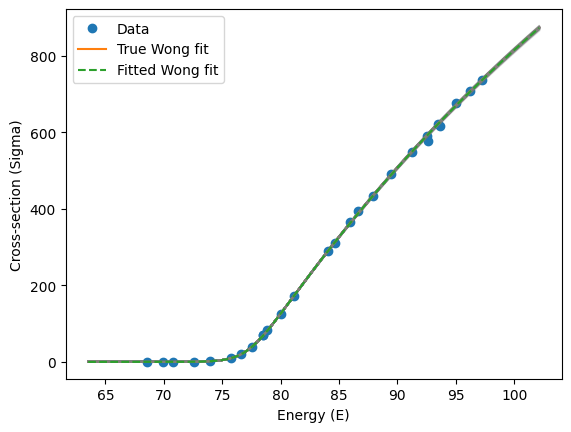

Text(0, 0.5, 'Barrier Distribution')

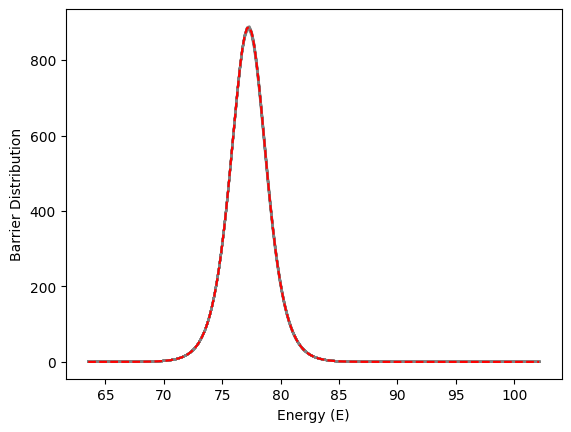

In [5]:
# Check 1.2: How does drawing samples from the fitted Wong look

i = 623
E_i, Sigma_i, Sigma_err_i, params_i = ds["get_i"](i) # note: uses init_E0 inside
popt, pcov, chi2 = fit_wong_with_restarts(E_i, Sigma_i, Sigma_err_i, n_restarts=5)
E_pred = make_x_pred(E_i)
samples = draw_sigma_samples(E_pred, popt, pcov, n_samples=100)
print("Fitted params:", popt)
print("True params:", params_i) 
print("Chi2:", chi2)

plt.plot(E_i, Sigma_i, 'o', label='Data')
plt.plot(E_pred, sigma(E_pred, *params_i), '-', label='True Wong fit')
for i in range(samples.shape[0]):
    plt.plot(E_pred, samples[i,:], color='gray', alpha=0.1)
plt.plot(E_pred, sigma(E_pred, *popt), '--', label='Fitted Wong fit')
plt.legend()
plt.xlabel('Energy (E)')  
plt.ylabel('Cross-section (Sigma)')
plt.show()


D_samples = barrier_from_sigma_samples(E_pred, samples)
D_true = barrier_from_sigma_samples(E_pred, sigma(E_pred, *params_i).reshape(1,-1))[0]
for i in range(D_samples.shape[0]):
    plt.plot(E_pred, D_samples[i,:], color='gray', alpha=0.1)   
plt.plot(E_pred, D_true, 'r--', label='True Barrier')
plt.xlabel('Energy (E)')
plt.ylabel('Barrier Distribution')


Fit 3: E0_fit = 66.45, E0_true = 66.46
Shapes: (500, 195)


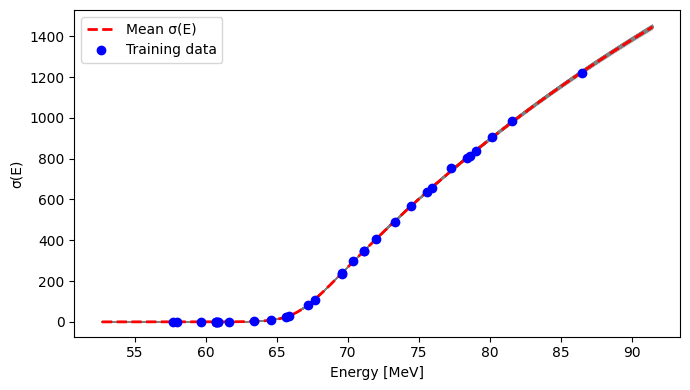

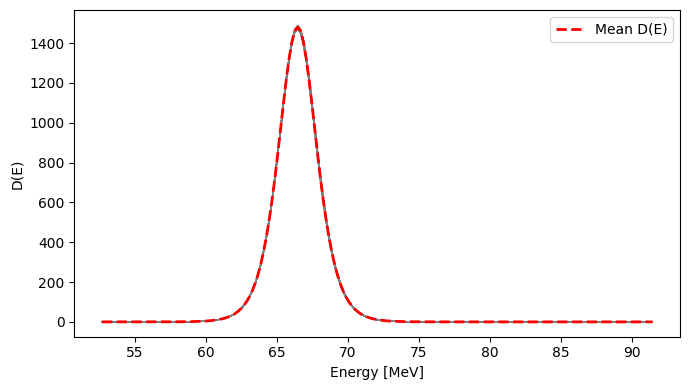

In [6]:
# Check 1.3: Check that we can visualize from loaded HDF5 results
import h5py 
h5_path = "/mnt/home/philipaa/scratch/barrier-paper-results/cv0.75_spacing1.0.h5_wong.h5"
fit_index = 3  # choose which fit to visualize

with h5py.File(h5_path, "r") as f:
    grp = f[f"{fit_index}"]

    # Load datasets lazily (HDF5 slicing works)
    x = grp["x_pred"][:]
    y_mean = grp["y_mean"][:]
    y_samples = grp["y_samples"][:]
    E_train = grp["E_data"][:]
    Sigma_train = grp["Sigma_data"][:]
    Sigma_err_train = grp["Sigma_err"][:]
    E0_fit = grp.attrs["E0_fit"]
    E0_true = grp.attrs["E0_true"]

print(f"Fit {fit_index}: E0_fit = {E0_fit:.2f}, E0_true = {E0_true:.2f}")
print("Shapes:", y_samples.shape)

# --- Plot σ(E) ---
plt.figure(figsize=(7,4))
for y in y_samples:
    plt.plot(x, y, color="gray", alpha=0.2, lw=0.7)
plt.plot(x, y_mean, "r--", lw=2, label="Mean σ(E)")
plt.plot(E_train, Sigma_train, "bo", label="Training data")

plt.xlabel("Energy [MeV]")
plt.ylabel("σ(E)")
plt.legend()
plt.tight_layout()
plt.show()

D_samples = barrier_from_sigma_samples(x, y_samples)
D_mean = barrier_from_sigma_samples(x, y_mean.reshape(1,-1))[0]
bands = percentile_bands(D_samples, levels=(0.68, 0.95))
D_lo = bands["lower_68"]
D_hi = bands["upper_68"]

plt.figure(figsize=(7,4))
for D in D_samples:
    plt.plot(x, D, color="gray", alpha=0.2, lw=0.7)
plt.plot(x, D_mean, "r--", lw=2, label="Mean D(E)")
plt.xlabel("Energy [MeV]")
plt.ylabel("D(E)")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic

def train_gp_bad(
    E, Sigma, Sigma_err,
    n_restarts=2, n_samples=200, random_state=None
):
    """
    GP regression on (E, Sigma) with simple RBF kernel and heteroscedastic noise via alpha=Sigma_err^2.
    Returns arrays for HDF5 writing: x_pred, y_mean, y_samples, and barrier-space summaries.
    """
    # --- defensives & shapes ---
    E = np.asarray(E, float).reshape(-1)
    Sigma = np.asarray(Sigma, float).reshape(-1)
    Sigma_err = np.asarray(Sigma_err, float).reshape(-1)

    # ensure sorted by energy (GP prefers monotonic X for some diagnostics)
    order = np.argsort(E)
    E, Sigma, Sigma_err = E[order], Sigma[order], Sigma_err[order]

    # --- kernel and GP ---
    # length scale bounds based on grid spacing; robust to irregular grids
    if len(E) > 1:
        dE = np.diff(E)
        ell_min = max(1e-3, np.min(np.abs(dE)))
        ell_max = max(5.0, 10.0 * np.median(np.abs(dE)))
    else:
        ell_min, ell_max = 1e-3, 10.0
    kernel = ConstantKernel()*RBF(length_scale=1.0, length_scale_bounds=(ell_min, ell_max))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=np.maximum(Sigma_err, 1e-12) ** 2,   # heteroscedastic obs noise
        n_restarts_optimizer=int(n_restarts),
        normalize_y=False,
        random_state=random_state,
    )

    # --- fit ---
    gp.fit(E.reshape(-1, 1), Sigma)
    kernel_opt = str(gp.kernel_)
    lml = float(getattr(gp, "log_marginal_likelihood_value_", np.nan))

    # --- prediction grid (match Wong plotting style) ---
    x_pred = np.arange(max(0.0, E.min() - 5.0), E.max() + 5.0, 0.2).astype(float)
    Xp = x_pred.reshape(-1, 1)

    # posterior mean and samples
    y_mean, _ = gp.predict(Xp, return_std=True)
    y_samples = gp.sample_y(Xp, n_samples=n_samples, random_state=random_state).T  # (S, M)

    return gp, ell_min, ell_max

def train_gp_good(E_train, sigma_mu_train, sigma_var_train, n_restarts=20, kernel=None, fixed_length=None, noise=None, log=False):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise.

    Parameters
    ----------
    E_train : array-like, shape (N,)
        Training energies.
    sigma_mu_train : array-like, shape (N,)
        Mean cross-section values at E_train.
    delta_sigma_train : array-like, shape (N,)
        Variance of cross-section at E_train (i.e., noise variances).
    n_restarts : int, optional (default=10)
        Number of restarts for the optimizer.

    Returns
    -------
    gp : GaussianProcessRegressor
        The fitted GP model.
    """
    # 1) Sort E_train for length-scale estimation
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = min(np.abs(dE))
    lbound, ubound = ell0 , 10.0

    # 2) Compute signal variance from the training mean
    var_y0 = np.var(sigma_mu_train)
    print(var_y0)

    if kernel is None:
        if fixed_length is not None:
            # FIXED correlation length
            k_rbf = ConstantKernel(constant_value_bounds=(1e-05, 10000000.0)) * RBF(
                length_scale=fixed_length,
                length_scale_bounds="fixed"
            )
        else:
            # Optimizable correlation length
            k_rbf = ConstantKernel(constant_value_bounds=(1e-05, 10000000.0)) * RBF(
                length_scale=1.0,
                length_scale_bounds=(lbound, ubound)
            )
        kernel  = k_rbf
        if noise: 
            k_noise = WhiteKernel(noise_level=1e-5 , noise_level_bounds=(1e-9, 1e-3))
            kernel  += k_noise

    if log: 
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha= sigma_var_train / sigma_mu_train**2,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.log(np.asarray(sigma_mu_train)))
    else:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.asarray(sigma_mu_train))

    return gp, lbound, ubound


from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel, WhiteKernel, RationalQuadratic
)

def train_gp_rq(
    E_train,
    sigma_mu_train,
    sigma_var_train,
    n_restarts=20,
    kernel=None,
    fixed_length=None,
    noise=None,
    log=False
):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise,
    using a Rational Quadratic kernel.

    Parameters
    ----------
    E_train : array-like (N,)
    sigma_mu_train : array-like (N,)
    sigma_var_train : array-like (N,)
        Noise variances at training points.
    """

    # ---- Sorting for length-scale bounds (not used for RQ but kept for consistency) ----
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = min(np.abs(dE))
    lbound, ubound = ell0, 10.0

    # signal variance (not used directly)
    var_y0 = np.var(sigma_mu_train)
    print("Var(y) =", var_y0)

    # ------------------------------------------------
    # Build Rational Quadratic kernel
    # ------------------------------------------------
    if kernel is None:
        if fixed_length is not None:
            # RQ with FIXED length scale
            k_rq = ConstantKernel(1.0, (1e-5, 1e5)) * RationalQuadratic(
                length_scale=fixed_length,
                length_scale_bounds="fixed",
                alpha=1.0,             # shape parameter
                alpha_bounds=(1e-12, 1e2)
            )
        else:
            # RQ with optimized length scale
            k_rq = ConstantKernel(1.0, (1e-5, 1e5)) * RationalQuadratic(
                length_scale=1.0,
                length_scale_bounds=(lbound, ubound),
                alpha=1.0,
                alpha_bounds=(1e-12, 1e2)
            )

        kernel = k_rq

        if noise:
            kernel += WhiteKernel(noise_level=1e-5, noise_level_bounds=(1e-9, 1e-3))

    # ------------------------------------------------
    # Build GP model
    # ------------------------------------------------
    if log:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train / sigma_mu_train**2,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1),
               np.log(np.asarray(sigma_mu_train)))
    else:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1),
               np.asarray(sigma_mu_train))

    return gp, lbound, ubound


[77.25473133 10.6833096   6.33971773]
Var(y) = 69226.11643485342
Correlation length bounds: 0.0010000000000047748 10.0


/mnt/ffs24/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


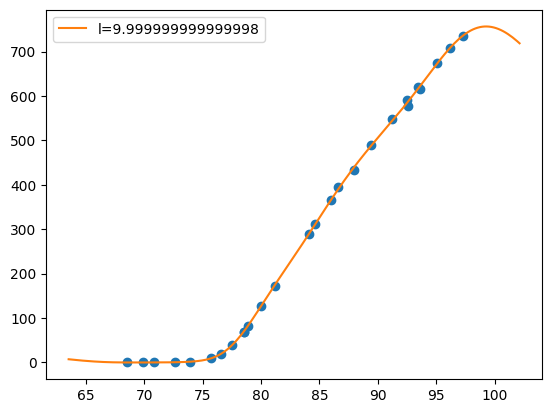

In [8]:
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

i = 623
data_path = "/mnt/home/philipaa/scratch/barrier-paper-datasets/cv0.75_spacing1.0.h5"
ds = load_packed_hdf5(data_path)
E, Sigma, Sigma_err, params_i = ds["get_i"](i) # note: uses init_E0 inside
print(params_i)
E0_true, R0_true, hw_true = params_i

E = np.asarray(E, float).reshape(-1)
Sigma = np.asarray(Sigma, float).reshape(-1)
Sigma_err = np.asarray(Sigma_err, float).reshape(-1)

# ensure sorted by energy (GP prefers monotonic X for some diagnostics)
order = np.argsort(E)
E, Sigma, Sigma_err = E[order], Sigma[order], Sigma_err[order]

gp, lmin, lmax  = train_gp_rq(E, Sigma, Sigma_err**2, n_restarts=20)
plt.plot(E, Sigma, 'o')  # training data
E_pred = make_x_pred(E)
#E_pred = np.linspace(min(E)-40, max(E)+100, 200)
print("Correlation length bounds:", lmin, lmax)
plt.plot(E_pred, gp.predict(E_pred.reshape(-1, 1)), label=f"l={gp.kernel_.k2.length_scale}")

plt.legend()  # warm-up predict

Fit 30: E0_fit = 66.45, E0_true = 53.38
Shapes: (500, 199)


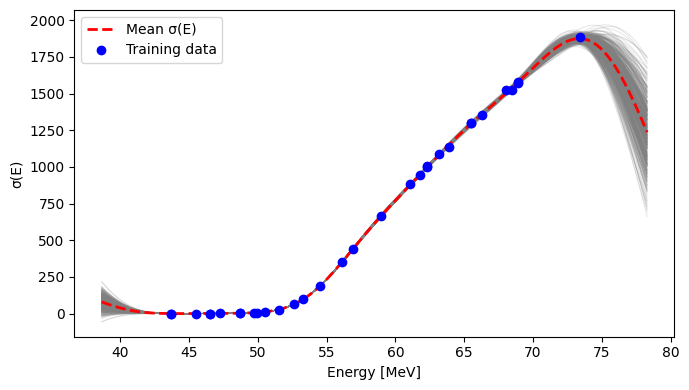

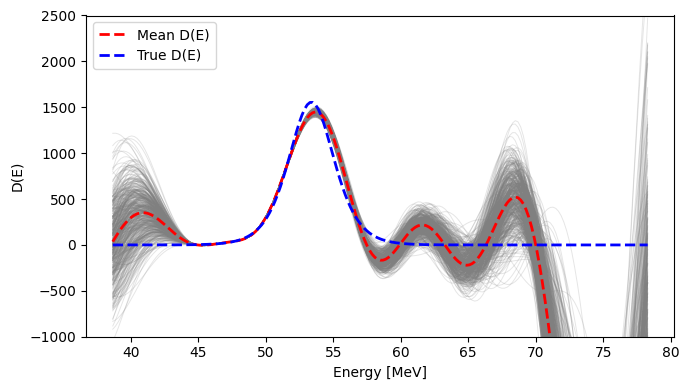

In [9]:
# Check 1.3: Check that we can visualize from loaded HDF5 results
import h5py 
h5_path = "/mnt/home/philipaa/scratch/barrier-paper-results/cv0.75_spacing1.0_gp.h5"
fit_index = 30  # choose which fit to visualize

with h5py.File(h5_path, "r") as f:
    grp = f[f"{fit_index}"]

    # Load datasets lazily (HDF5 slicing works)
    x = grp["x_pred"][:]
    y_mean = grp["y_mean"][:]
    y_samples = grp["y_samples"][:]
    E_train = grp["E_data"][:]
    Sigma_train = grp["Sigma_data"][:]
    Sigma_err_train = grp["Sigma_err"][:]
    E0_true = grp.attrs["E0_true"]
    R0_true = grp.attrs["R0_true"]
    hw_true = grp.attrs["hw_true"]

print(f"Fit {fit_index}: E0_fit = {E0_fit:.2f}, E0_true = {E0_true:.2f}")
print("Shapes:", y_samples.shape)

# --- Plot σ(E) ---
plt.figure(figsize=(7,4))
for y in y_samples:
    plt.plot(x, y, color="gray", alpha=0.2, lw=0.7)
plt.plot(x, y_mean, "r--", lw=2, label="Mean σ(E)")
plt.plot(E_train, Sigma_train, "bo", label="Training data")

plt.xlabel("Energy [MeV]")
plt.ylabel("σ(E)")
plt.legend()
plt.tight_layout()
plt.show()

D_samples = barrier_from_sigma_samples(x, y_samples)
D_mean = barrier_from_sigma_samples(x, y_mean.reshape(1,-1))[0]
bands = percentile_bands(D_samples, levels=(0.68, 0.95))
D_lo = bands["lower_68"]
D_hi = bands["upper_68"]

plt.figure(figsize=(7,4))
for D in D_samples:
    plt.plot(x, D, color="gray", alpha=0.2, lw=0.7)
plt.plot(x, D_mean, "r--", lw=2, label="Mean D(E)")

sigma_true = sigma(x, E0=E0_true, R0=R0_true, hbarw=hw_true)

D_true = barrier_from_sigma_samples(x, sigma_true.reshape(1,-1))[0]
plt.plot(x, D_true, "b--", lw=2, label="True D(E)")
#plt.xlim(E_train.min(), E_train.max())
plt.ylim(-1000, 2500)
plt.xlabel("Energy [MeV]")
plt.ylabel("D(E)")
plt.legend()
plt.tight_layout()
plt.show()

# Visualizing Poor Fits
### A: BNNs

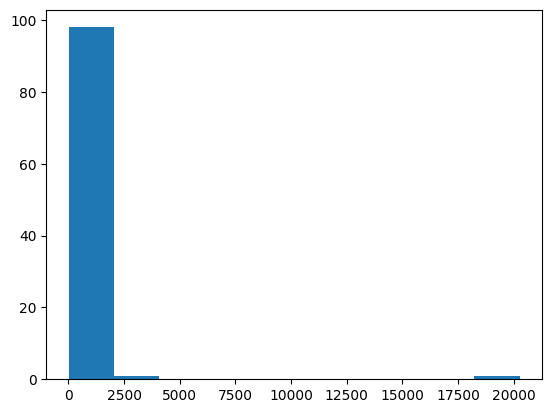

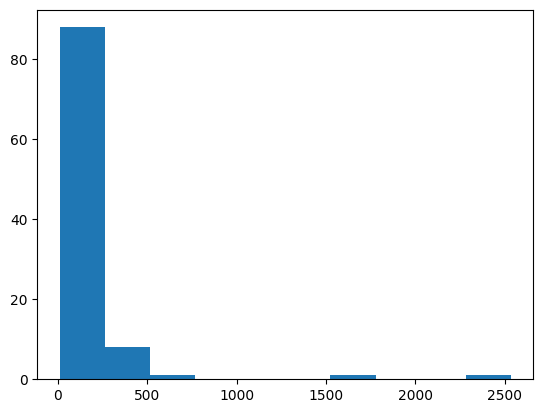

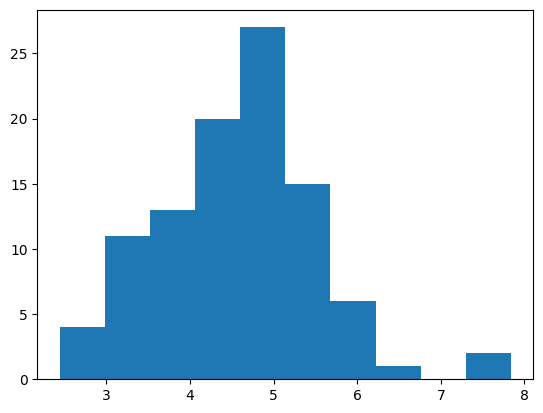

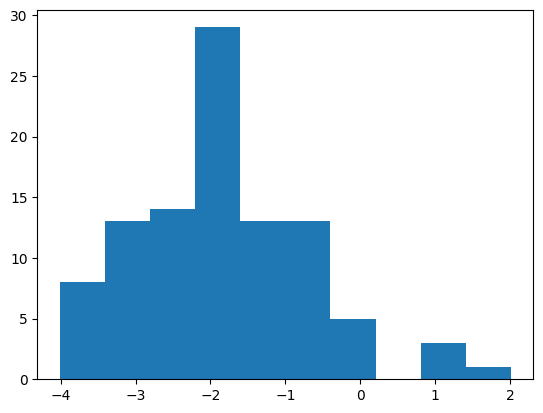

In [10]:
import pandas as pd
path_base = "/mnt/home/philipaa/scratch/barrier-paper-results/res_2.00MeV_noise0.01_" #res_0.25MeV_noise0.02_
h5_path = path_base + "bnn_soc.h5"
csv_path = h5_path + ".csv"

df = pd.read_csv(csv_path)
rmse_bnns = df['barrier_RMSE']
norm = df['hw_true'] * (df['R0_true'] ** 2)
plt.hist(rmse_bnns)
plt.show()

bad_mask = rmse_bnns > 20000
pruned_rmse_bnns = rmse_bnns[~bad_mask]
plt.hist(pruned_rmse_bnns)
plt.show()

plt.hist(np.log(pruned_rmse_bnns))
plt.show()

plt.hist(np.log(pruned_rmse_bnns/norm))
plt.show()

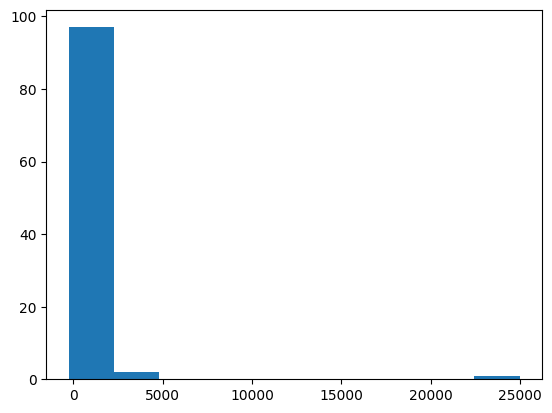

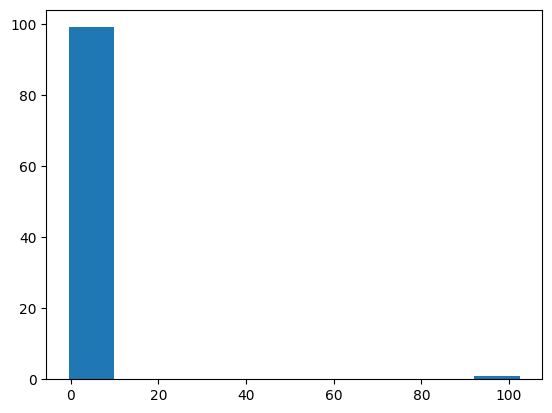

Index([62, 72, 92], dtype='int64')
Index([62, 72, 92], dtype='int64')
RMSE before pruning: 2537.694589355738 10.290221328539628
RMSE after pruning: 134.533394251369 0.5218666685243761


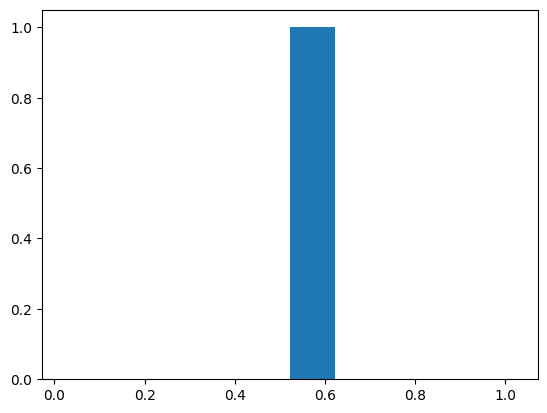

Removed rows: 3
Fraction removed: 0.03
[9.17648583e-09 7.37593570e-07 6.07835388e-05 5.06199962e-03
 4.05837766e-01 2.34082120e+01 1.44769910e+02 2.77912806e+02
 4.09513244e+02 5.20197137e+02 6.16897780e+02 7.39041631e+02
 8.25053711e+02 9.08532384e+02 1.00929820e+03 1.06662960e+03]


KeyError: "Unable to synchronously open object (object 'd2_samples' doesn't exist)"

In [ ]:
import pandas as pd
path_base = "/mnt/home/philipaa/scratch/barrier-paper-results/res_2.00MeV_noise0.01_" #res_0.25MeV_noise0.02_
h5_path = path_base + "bnn_soc.h5"
csv_path = h5_path + ".csv"

df = pd.read_csv(csv_path)
err = (df['barrier_peak_ht_pred'] - df['barrier_peak_ht_true'] )
norm = df['R0_true']**2 * df['hw_true']
norm_err = (df['barrier_peak_ht_pred'] - df['barrier_peak_ht_true'] ) / norm
plt.hist(err)
plt.show()
plt.hist(norm_err)
plt.show()
bad_idx = df.index[np.abs(err) > 1000]
print(bad_idx)


cutoff = 1000
bad_idx = df.index[np.abs(err) > cutoff]
print(bad_idx)

rmse_before = np.sqrt(np.mean(err**2))
norm_rmse_before = np.sqrt(np.mean(norm_err**2))
print("RMSE before pruning:", rmse_before, norm_rmse_before)
bad_mask = np.abs(err) > cutoff
rmse_after = np.sqrt(np.mean(err[~bad_mask]**2))
norm_rmse_after = np.sqrt(np.mean(norm_err[~bad_mask]**2))
print("RMSE after pruning:", rmse_after, norm_rmse_after)

plt.hist(np.sqrt(np.mean(norm_err[~bad_mask]**2)))
plt.show()
print("Removed rows:", bad_mask.sum())
print("Fraction removed:", bad_mask.mean())

import h5py 
idx = bad_idx[1]
with h5py.File(h5_path, "r") as f:
    grp = f[str(int(idx))]

    # Load arrays
    x = grp["x_pred"][:]
    y_mean = grp["y_mean"][:]
    y_samples = grp["y_samples"][:]
    E_data = grp["E_data"][:]
    Sigma_data = grp["Sigma_data"][:]
    Sigma_err = grp["Sigma_err"][:]
    E0_true = float(grp.attrs["E0_true"])
    R0_true = float(grp.attrs["R0_true"])
    hw_true = float(grp.attrs["hw_true"])
    E0_fit = float(grp.attrs.get("E0_fit", np.nan))
    print(Sigma_data)

    D_samples = barrier_from_sigma_samples(x, y_samples)
    D_mean = barrier_from_sigma_samples(x, y_mean.reshape(1, -1))[0]
    sigma_true = sigma(x, E0=E0_true, R0=R0_true, hbarw=hw_true)
    D_true = barrier_from_sigma_samples(x, sigma_true.reshape(1, -1))[0]

    plt.plot(E_data, Sigma_data, 'o')
    plt.plot(x, y_mean)
    plt.title(f"Height Error: {err[idx]}")
    plt.show()


    plt.plot(x, D_true, 'b')
    plt.plot(x, D_mean, "--r")



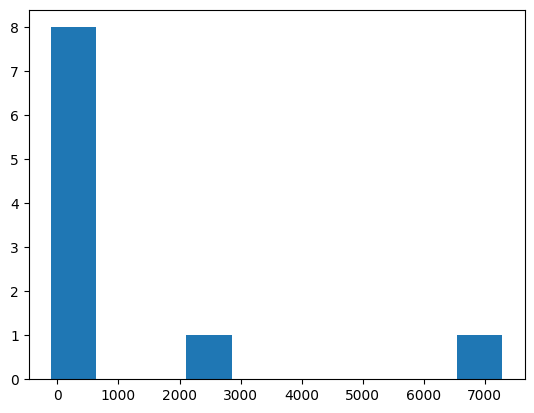

Index([5, 9], dtype='int64')
Index([5, 9], dtype='int64')
RMSE before pruning: 2420.0193968353287
RMSE after pruning: 99.15760622970943
Removed rows: 2
Fraction removed: 0.2
[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


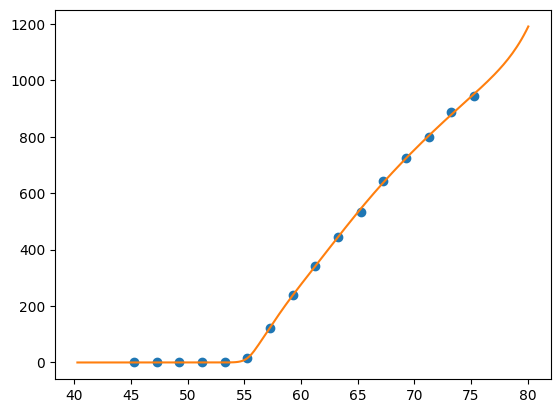

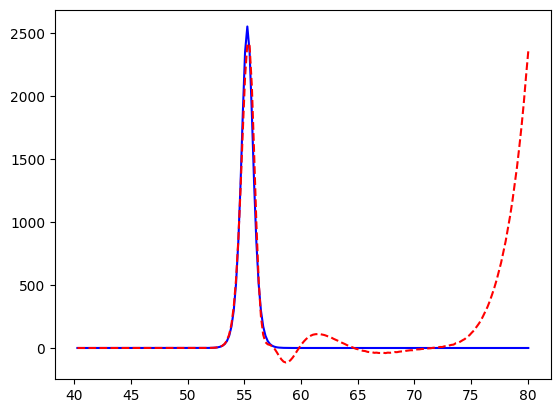

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


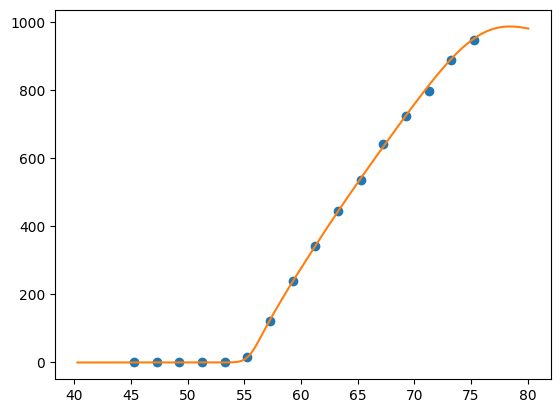

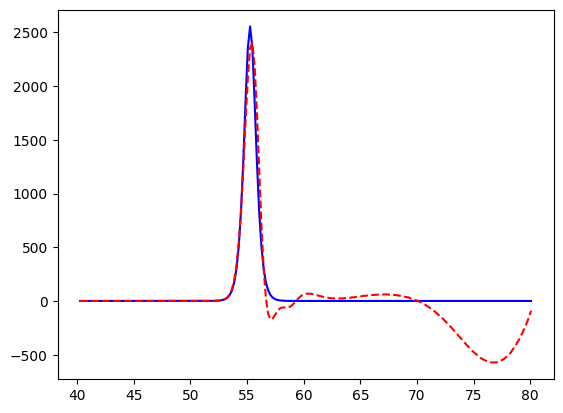

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


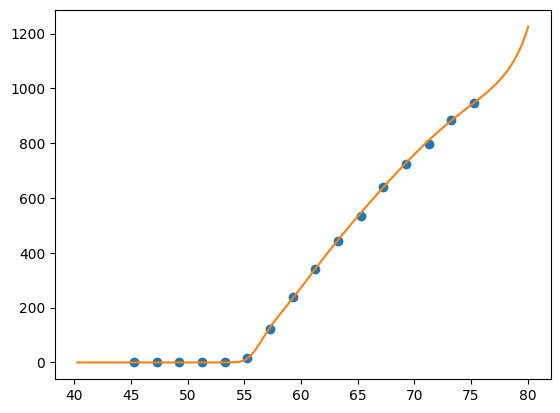

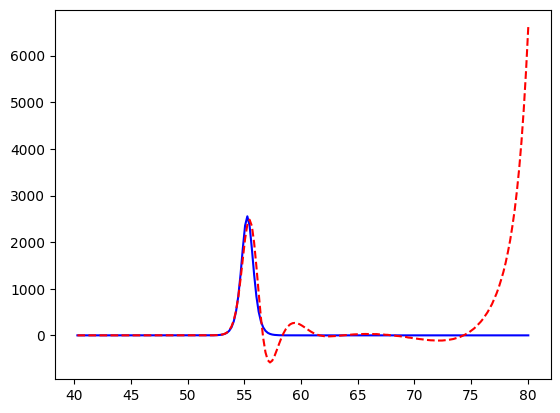

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


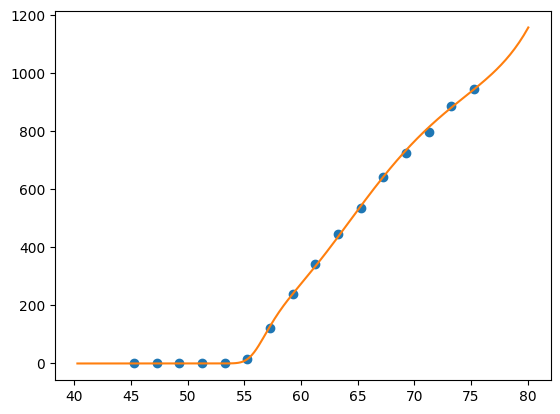

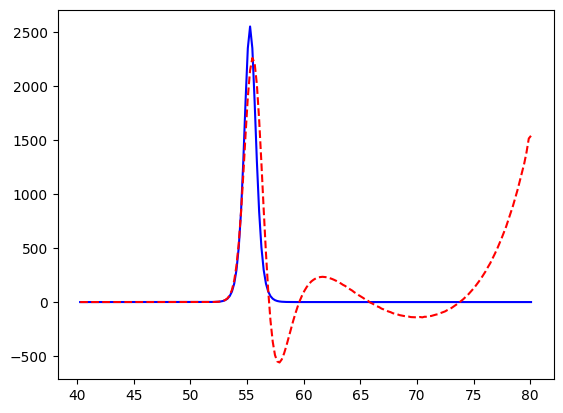

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


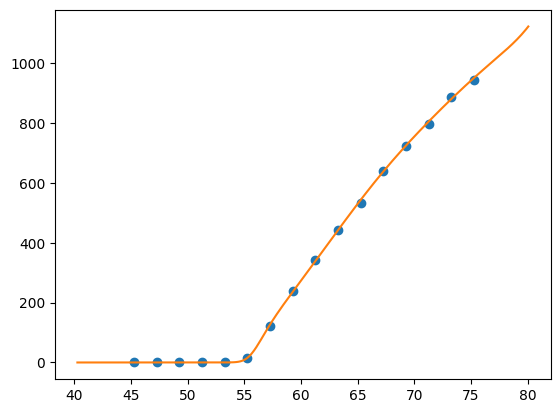

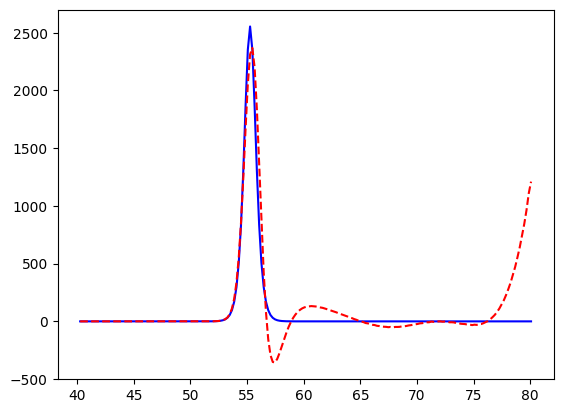

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


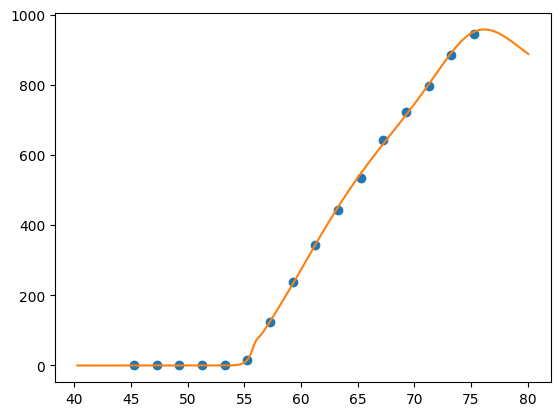

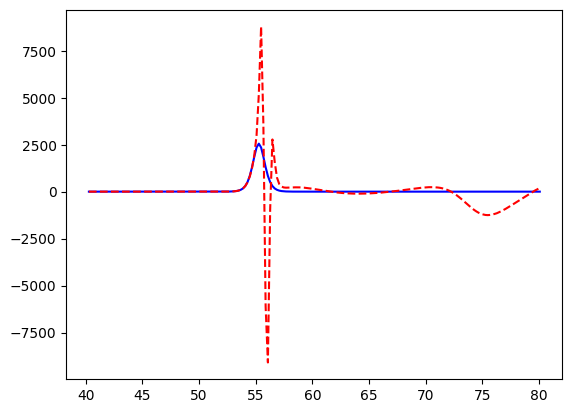

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


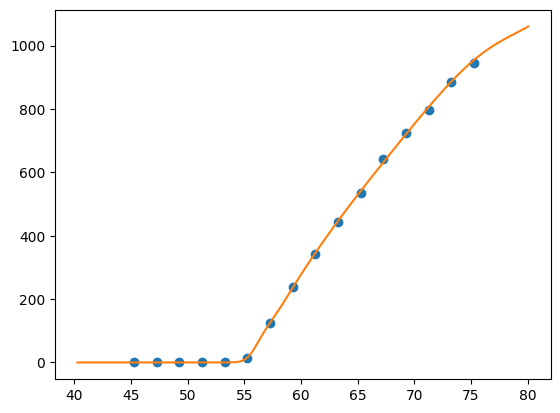

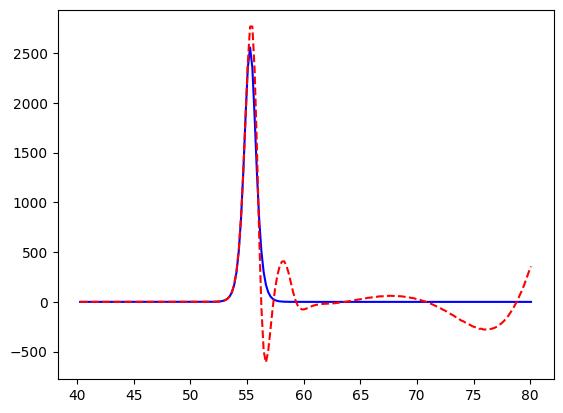

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


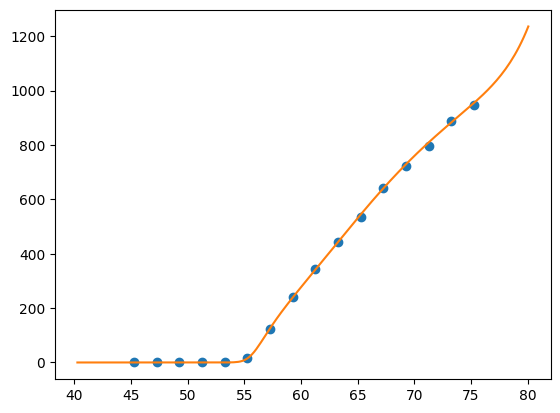

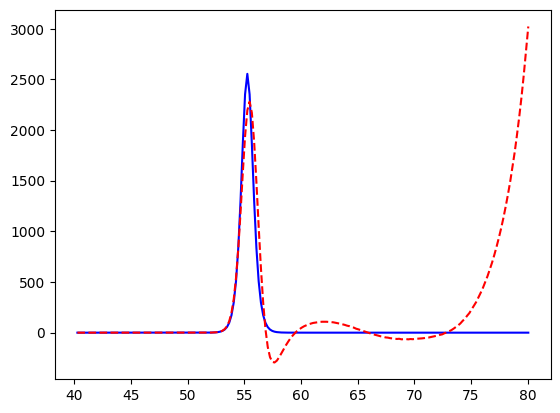

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


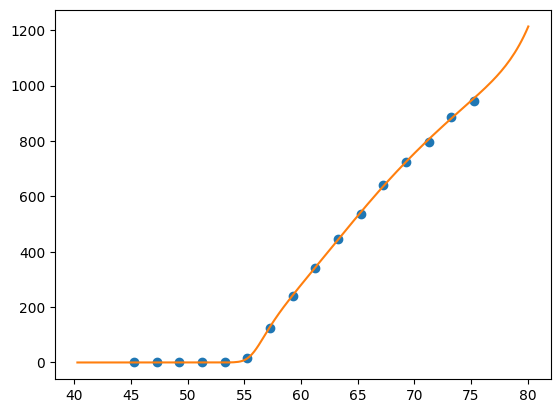

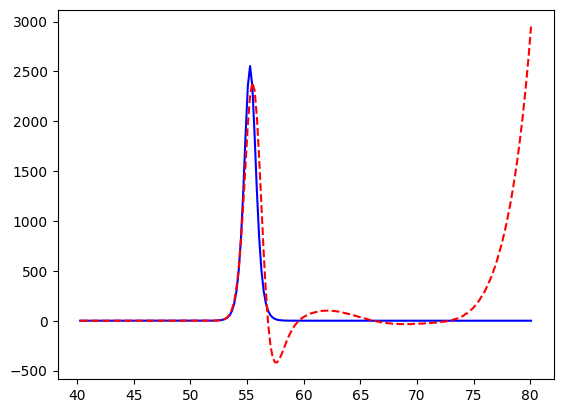

[7.12866232e-12 2.23575810e-09 7.05376437e-07 2.20702449e-04
 6.95101213e-02 1.54608719e+01 1.23054073e+02 2.39292392e+02
 3.42818006e+02 4.44627979e+02 5.34490593e+02 6.41769888e+02
 7.23694012e+02 7.97683530e+02 8.86396724e+02 9.45755986e+02]


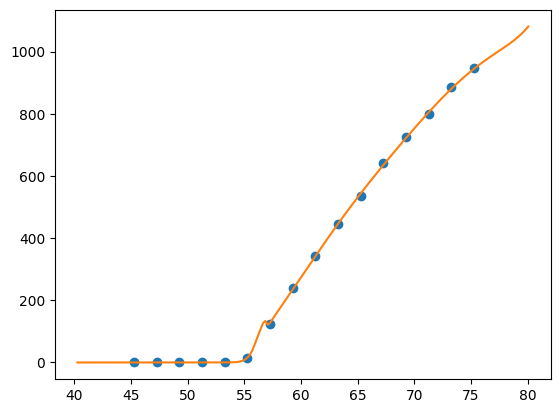

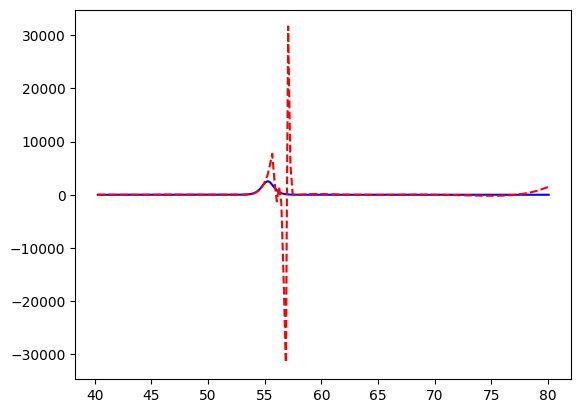

In [12]:
import pandas as pd
idx = 62
path_base = "/mnt/home/philipaa/scratch/barrier-paper-results/"
h5_path = path_base + f"res_2.00MeV_noise0.01_bnn_soc_idx{idx}.h5"
csv_path = h5_path + ".csv"

df = pd.read_csv(csv_path)
err = df['barrier_peak_ht_pred'] - df['barrier_peak_ht_true']
plt.hist(err)
plt.show()
bad_idx = df.index[np.abs(err) > 1000]
print(bad_idx)


cutoff = 1000
bad_idx = df.index[np.abs(err) > cutoff]
print(bad_idx)

rmse_before = np.sqrt(np.mean(err**2))
print("RMSE before pruning:", rmse_before)
bad_mask = np.abs(err) > cutoff
rmse_after = np.sqrt(np.mean(err[~bad_mask]**2))
print("RMSE after pruning:", rmse_after)

print("Removed rows:", bad_mask.sum())
print("Fraction removed:", bad_mask.mean())

import h5py 
for sub_idx in range(1,11):
#sub_idx = 7#bad_idx[0]
    group_name = f"{int(idx):05d}_run{int(sub_idx):02d}"
    with h5py.File(h5_path, "r") as f:
        grp = f[group_name]

        # Load arrays
        x = grp["x_pred"][:]
        y_mean = grp["y_mean"][:]
        y_samples = grp["y_samples"][:]
        E_data = grp["E_data"][:]
        Sigma_data = grp["Sigma_data"][:]
        Sigma_err = grp["Sigma_err"][:]
        E0_true = float(grp.attrs["E0_true"])
        R0_true = float(grp.attrs["R0_true"])
        hw_true = float(grp.attrs["hw_true"])
        E0_fit = float(grp.attrs.get("E0_fit", np.nan))
        print(Sigma_data)

        D_samples = barrier_from_sigma_samples(x, y_samples)
        D_mean = barrier_from_sigma_samples(x, y_mean.reshape(1, -1))[0]
        sigma_true = sigma(x, E0=E0_true, R0=R0_true, hbarw=hw_true)
        D_true = barrier_from_sigma_samples(x, sigma_true.reshape(1, -1))[0]

        plt.plot(E_data, Sigma_data, 'o')
        plt.plot(x, y_mean)
    # plt.title(f"Height Error: {err[idx]}")
        plt.show()


        plt.plot(x, D_true, 'b')
        plt.plot(x, D_mean, "--r")
        plt.show()


### B: GPs

In [15]:
h5_path = path_base + "gp_rbf.h5"
csv_path = h5_path + ".csv"

df = pd.read_csv(csv_path)
err = df['barrier_peak_ht_pred'] - df['barrier_peak_ht_true']
plt.hist(err)
plt.show()


cutoff = 800
bad_idx = df.index[np.abs(err) > cutoff]
print(bad_idx)

rmse_before = np.sqrt(np.mean(err**2))
print("RMSE before pruning:", rmse_before)
bad_mask = np.abs(err) > cutoff
rmse_after = np.sqrt(np.mean(err[~bad_mask]**2))
print("RMSE after pruning:", rmse_after)

print("Removed rows:", bad_mask.sum())
print("Fraction removed:", bad_mask.mean())

import h5py 

with h5py.File(h5_path, "r") as f:
    grp = f[str(int(idx))]

    # Load arrays
    x = grp["x_pred"][:]
    y_mean = grp["y_mean"][:]
    y_samples = grp["y_samples"][:]
    E_data = grp["E_data"][:]
    Sigma_data = grp["Sigma_data"][:]
    Sigma_err = grp["Sigma_err"][:]
    E0_true = float(grp.attrs["E0_true"])
    R0_true = float(grp.attrs["R0_true"])
    hw_true = float(grp.attrs["hw_true"])
    E0_fit = float(grp.attrs.get("E0_fit", np.nan))

    D_samples = barrier_from_sigma_samples(x, y_samples)
    D_mean = barrier_from_sigma_samples(x, y_mean.reshape(1, -1))[0]
    sigma_true = sigma(x, E0=E0_true, R0=R0_true, hbarw=hw_true)
    D_true = barrier_from_sigma_samples(x, sigma_true.reshape(1, -1))[0]


    plt.plot(E_data, Sigma_data, 'o')
    plt.plot(x, y_mean)
    plt.title(f"Height Error: {err[idx]}")
    plt.show()


    plt.plot(x, D_true, 'b')
    plt.plot(x, D_mean, "--r")

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/home/philipaa/scratch/barrier-paper-results/experiments6gp_rbf.h5.csv'